# Plot results: see what an estimate's numbers hide

## At a glance

A table of estimates hides shape. It hides where patients had almost no chance of an offer, how the
estimate moves when you change a setting, and how often a method's interval misses. The functions in
`cleverly.plotting` draw those shapes. This page uses them on simulated data, where offering
care-transition navigation to patients going home from hospital raised a transition score by a true
1.0 point. The fit estimates 1.093 points, with a 95% confidence interval of 0.961 to 1.225, and the
figures check and stress that answer.

Every figure draws only numbers the fit holds. A method that reports no interval gets a hollow point
and a reason, never an invented interval. Each section asks one question, shows the code and the
figure, prints the numbers behind it, and says how to read it. The main caveat is that a figure
checks the fitted models and the characteristics you recorded. It cannot show a confounder, a
missing factor that drove both the offer and the score, that nobody recorded. The figures need
matplotlib, so run `pip install "cleverly[plot]"` first.

## Set up

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression

import cleverly
from cleverly import plotting

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
print("cleverly", cleverly.__version__)

cleverly 0.2.0


## The data

In [2]:
from cleverly.datasets import make_weak_overlap

# With your own data, load your data frame here, such as frame = pd.read_csv(...).
# Real data have no `truth`, so drop every line that uses it.
frame, truth = make_weak_overlap(n=1_500, seed=21, strength=1.5)
frame = frame.rename(
    columns={
        "Y": "transition_score",
        "A": "navigation_offer",
        "W1": "discharge_risk",
        "W2": "prior_utilization",
        "W3": "medication_burden",
    }
)
covariates = ["discharge_risk", "prior_utilization", "medication_burden"]
print("rows and columns:", frame.shape)
print("column names:", list(frame.columns))
print(frame.head().round(3))
print()
print(f"share offered navigation: {frame['navigation_offer'].mean():.3f}")
print(f"true average effect of the offer (simulated data only): {truth['ate']:.3f}")

rows and columns: (1500, 5)
column names: ['transition_score', 'navigation_offer', 'discharge_risk', 'prior_utilization', 'medication_burden']
   transition_score  navigation_offer  discharge_risk  prior_utilization  medication_burden
0             3.512               1.0           0.359              1.511             -1.786
1             5.694               1.0           1.687             -0.047             -0.800
2            -1.508               0.0          -0.803             -1.083             -0.224
3             5.013               1.0           0.834              0.584              0.638
4            -0.363               0.0          -1.695             -1.571              1.554

share offered navigation: 0.489
true average effect of the offer (simulated data only): 1.000


One row is one patient discharged home. The score is on a simulated scale with no fixed range, so it
counts points. Discharge teams offered navigation mostly to riskier patients, so the two groups
differ before the offer, and some patients were almost always or almost never offered. The columns
come from `make_weak_overlap`. The true effect, 1.000 points, is known only because the data are
simulated.

## One fit to draw

In [3]:
from cleverly import ATE, CausalStudy, PointTreatment

# For your own data, change the column names and swap in your own learners. Leave out
# cross_fit=False, so that each row's predictions come from models trained without it.
study = CausalStudy(
    frame,
    design=PointTreatment(
        outcome="transition_score",
        treatment="navigation_offer",
        adjustment=tuple(covariates),
    ),
)
# The average effect (ATE): the offered group (1) against the not-offered group (reference 0).
effect = study.identify(ATE(reference=0))
fit_settings = {
    "outcome_learner": LinearRegression(),
    "treatment_learner": LogisticRegression(max_iter=1000),
    "cross_fit": False,
    "random_state": 21,
}
result = effect.estimate(**fit_settings)
table = result.to_frame()[["estimand", "psi", "std_err", "ci_lower", "ci_upper"]]
print(table.round(3).to_string(index=False))

estimand   psi  std_err  ci_lower  ci_upper
     ate 1.093    0.068     0.961     1.225


The question is the average effect of the offer (ATE): how much the average score would change if
every patient were offered navigation, compared with no one. `cleverly` estimates it with targeted
maximum likelihood (TMLE). It fits an outcome model, which predicts the score from the offer and the
three characteristics, and a treatment model, which predicts who got the offer. A correction step
then uses the treatment model to remove the bias that the outcome model leaves, giving more weight to
patients whose own offer was unlikely. The estimate of 1.093 points, with a 95% interval of 0.961 to
1.225, covers the true 1.000.

Both models are plain regressions, and `cross_fit=False` has them predict the rows they were trained
on, which keeps the page fast. On your own data, leave that argument out, so that each row's
predictions come from models trained without that row.

## How large is the effect, and how sure are we?

        method   psi  ci_lower  ci_upper
          TMLE 1.093     0.961     1.225
weighting only 1.192      none      none
true average effect: 1.000


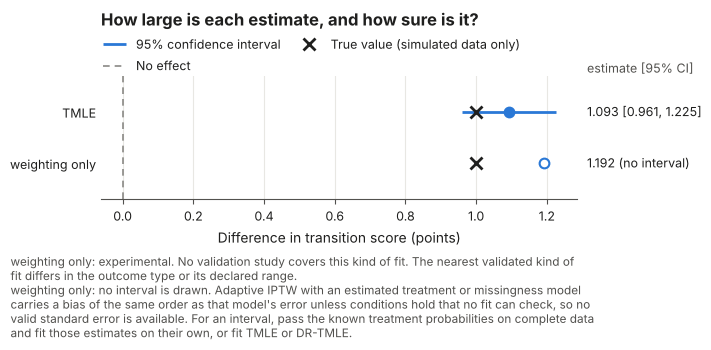

In [4]:
from cleverly import AdaptiveIPTWMethod, CrossFitting, ModelSpec, Runtime

# A second estimate of the same effect that only reweights patients and fits no outcome model.
weighting = effect.estimate(
    method=AdaptiveIPTWMethod(
        models=ModelSpec(treatment_learner=LogisticRegression(max_iter=1000)),
        cross_fitting=CrossFitting(enabled=False),
        runtime=Runtime(random_state=21, n_jobs=1),
        reduced_outcome_learner=LinearRegression(),
    )
)
fits = {"TMLE": result, "weighting only": weighting}
estimates = pd.concat(
    [fit.to_frame().assign(method=name) for name, fit in fits.items()], ignore_index=True
)
columns = ["method", "psi", "ci_lower", "ci_upper"]
print(estimates[columns].round(3).to_string(index=False, na_rep="none"))
print(f"true average effect: {truth['ate']:.3f}")
forest_fig = plotting.forest(
    result,
    weighting,
    labels=list(fits),
    outcome_label="transition score",
    units="points",
    truth=truth["ate"],
)

Each row is one estimate: a dot, a line for its 95% confidence interval, and the numbers on the
right. The dashed line marks no effect. The black cross marks the true value (`truth=`), which only
simulated data have, and the TMLE interval contains it.

The second row only reweights patients by their chance of the offer. It has a hollow dot and no line,
because `cleverly` reports no interval for it: with an estimated treatment model, no standard error
is known to be valid. The note under the figure gives that reason and calls the estimate
experimental, meaning no simulation study covers that kind of fit.

## Did every kind of patient have a chance of the offer?

predicted chance of the offer, by who was actually offered:
            offered  not offered
percentile                      
5%            0.200        0.025
25%           0.497        0.109
50%           0.741        0.254
75%           0.888        0.468
95%           0.975        0.763

limits on the chance: 0.018 to 0.982
share of patients capped at a limit: 0.031


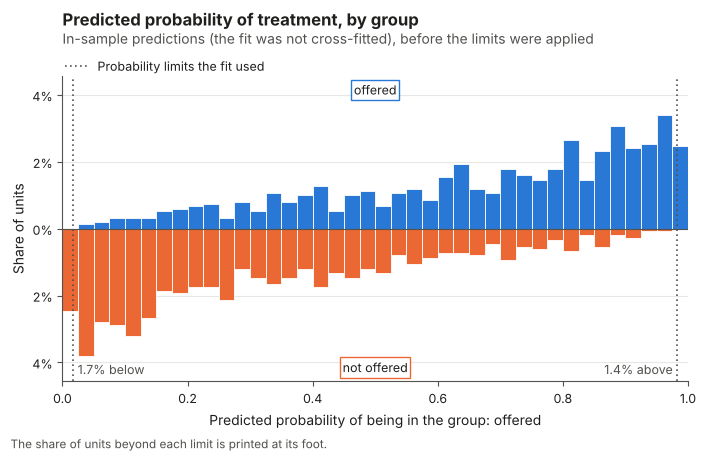

In [5]:
support = result.diagnostics.support()
chances = pd.DataFrame(support.propensity_quantiles).loc[[0.05, 0.25, 0.5, 0.75, 0.95]]
chances = chances[["treated", "control"]]
chances.columns = ["offered", "not offered"]
chances.index = ["5%", "25%", "50%", "75%", "95%"]
chances.index.name = "percentile"
print("predicted chance of the offer, by who was actually offered:")
print(chances.round(3))
print()
low, high = support.bounds
print(f"limits on the chance: {low:.3f} to {high:.3f}")
print(f"share of patients capped at a limit: {support.truncated['fraction']:.3f}")
overlap_fig = plotting.overlap(result, labels={1: "offered", 0: "not offered"})

The treatment model gives each patient a predicted chance of the offer. The figure stacks offered
patients above the axis and the others below it, so the groups overlap where both have bars at the
same chance. Only 5% of the offered patients had a chance below 0.200. Half of the patients not
offered had a chance below 0.254, so patients like the offered ones are scarce at the low end. The
dotted lines mark the limits `cleverly` put on the chances, 0.018 and 0.982, so that no patient's
weight grows without bound. The limits bind for 0.031 of the patients.

The chances come from a logistic regression on three recorded characteristics, so a kind of patient
that it does not describe is invisible here.

## Did weighting make the two groups alike?

        covariate  smd_unweighted  smd_weighted
   discharge_risk           1.123         0.056
prior_utilization           0.720         0.185
medication_burden           0.022         0.032


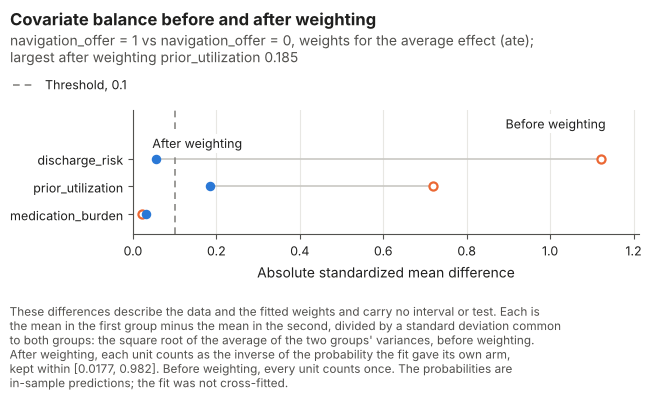

In [6]:
from cleverly.sensitivity import covariate_balance

balance = covariate_balance(result)
differences = balance.to_frame()[["covariate", "smd_unweighted", "smd_weighted"]]
print(differences.round(3).to_string(index=False))
balance_fig = balance.plot()

Each row is one characteristic. The hollow marker is the difference between the offered and
not-offered groups' averages, in standard deviations, before weighting. The filled marker is the same
difference after weighting each patient by the inverse of the chance of their own group, as the fit
does. A filled marker left of the dashed line at 0.1 is small by the usual rule of thumb.

Discharge risk falls from 1.123 to 0.056, so weighting removed most of the difference that drove the
offers. Prior utilization falls from 0.720 to 0.185, still above the line, so the weights have not
fully removed it. The usual response is a more flexible treatment model for that characteristic. The
figure describes these data and weights, with no interval or test.

## Does the answer depend on how extreme weights are capped?

 bound   psi  ci_lower  ci_upper  truncated_fraction
 0.001 1.118     0.982     1.253               0.000
 0.005 1.104     0.971     1.237               0.005
 0.010 1.099     0.966     1.231               0.013
 0.018 1.093     0.961     1.225               0.031
 0.025 1.088     0.955     1.220               0.049
 0.050 1.059     0.931     1.187               0.123
 0.100 1.026     0.910     1.142               0.238
 0.200 1.003     0.900     1.107               0.464


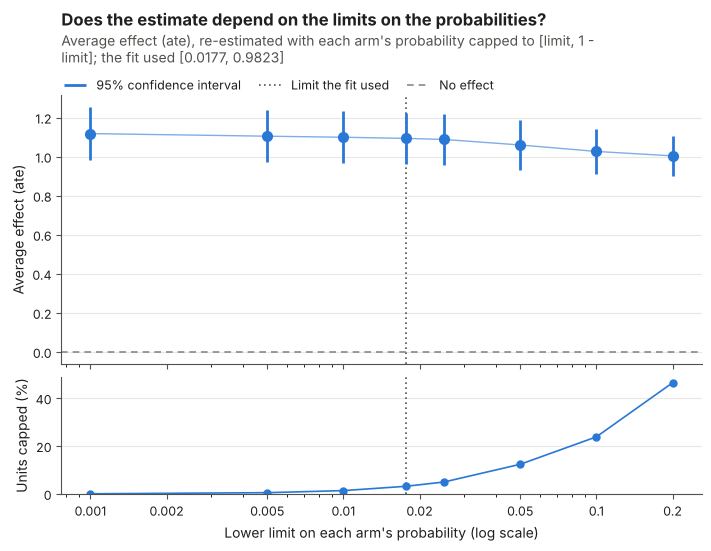

In [7]:
truncation = result.diagnostics.truncation_curve()
columns = ["bound", "psi", "ci_lower", "ci_upper", "truncated_fraction"]
print(truncation.to_frame()[columns].round(3).to_string(index=False))
truncation_fig = truncation.plot()

The top panel re-estimates the effect under each lower limit on the chance of the offer, with the
mirror image above, and the dotted line marks the limit the fit used. The bottom panel shows the
share of patients each limit caps. The estimate moves from 1.118 under the loosest cap to 1.003 under
the tightest, which caps 0.464 of patients, and every interval stays well above zero.

A tighter cap steadies the weights but can move the estimate when the true chances lie beyond the
limit. Look for a curve that stays flat across the caps you would defend. This one drifts by about
0.1 point and keeps the same conclusion.

## What if the offer were made more or less likely?

                                     estimand    psi  ci_lower  ci_upper
      ate_ipsi[half the odds vs current odds] -0.106    -0.122    -0.091
    ate_ipsi[double the odds vs current odds]  0.106     0.090     0.122
ate_ipsi[four times the odds vs current odds]  0.204     0.173     0.235


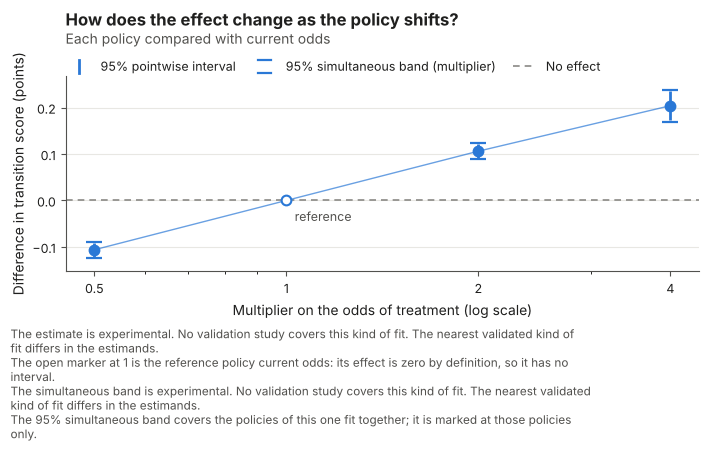

In [8]:
from cleverly import IncrementalEffect
from cleverly.interventions import Incremental

# For your own data, list the odds multipliers you could act on. 1.0 is today's practice.
odds_policies = IncrementalEffect(
    (
        Incremental(1.0, name="current odds"),
        Incremental(0.5, name="half the odds"),
        Incremental(2.0, name="double the odds"),
        Incremental(4.0, name="four times the odds"),
    ),
    reference="current odds",
)
policy_result = study.identify(odds_policies).estimate(**fit_settings)
policy_table = policy_result.to_frame()[["estimand", "psi", "ci_lower", "ci_upper"]]
print(policy_table.round(3).to_string(index=False))
policy_fig = plotting.curve(
    policy_result, outcome_label="transition score", units="points", treatment_label="the offer"
)

Instead of offering everyone or no one, this question multiplies each patient's odds of the offer,
which gives a family of policies that one fit answers together. Each dot compares a policy with
today's practice, the open marker at 1, whose effect is zero by definition. The effect rises with
the multiplier: -0.106 points at half the odds, 0.106 at double, and 0.204 at four times.

The thin bars are 95% intervals for each policy alone, and the capped bars are a band that covers
the three policies together. The note under the figure calls this kind of fit experimental. Raising
odds never gives a patient an offer they had no chance of, so this question needs no overlap
condition.

## How strong would a missing confounder have to be?

estimate as a risk ratio: 1.506; nearest interval limit: 1.433
E-value of the estimate: 2.38
E-value of the interval limit: 2.22


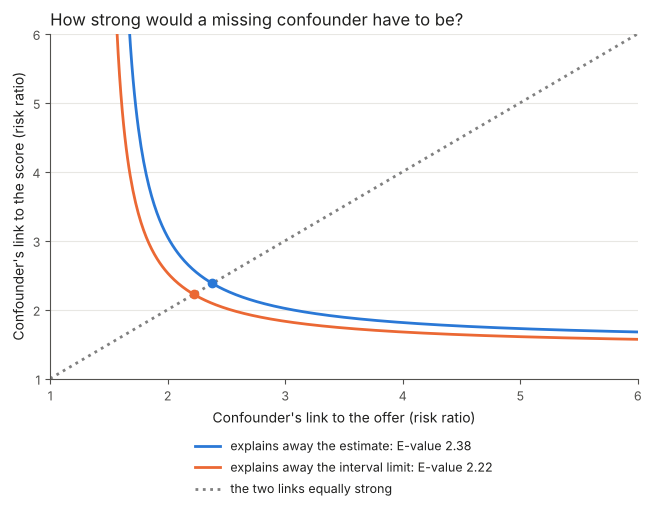

In [9]:
evalue = result.sensitivity.evalue()
low_limit = evalue.risk_ratio_ci[0]
print(f"estimate as a risk ratio: {evalue.risk_ratio:.3f}; nearest interval limit: {low_limit:.3f}")
print(f"E-value of the estimate: {evalue.point:.2f}")
print(f"E-value of the interval limit: {evalue.limit:.2f}")


def partner_strength(ratio, strengths):
    """The link to the score that, with a given link to the offer, explains `ratio` away."""
    return ratio * (strengths - 1.0) / (strengths - ratio)


with plotting.style():
    evalue_fig, ax = plt.subplots(figsize=(6.4, 5.0), layout="constrained")
    for ratio, value, label, color in (
        (evalue.risk_ratio, evalue.point, "the estimate", plotting.PALETTE[0]),
        (low_limit, evalue.limit, "the interval limit", plotting.PALETTE[1]),
    ):
        strengths = np.linspace(ratio + 0.02, 6.0, 400)
        ax.plot(
            strengths,
            partner_strength(ratio, strengths),
            color=color,
            label=f"explains away {label}: E-value {value:.2f}",
        )
        ax.plot([value], [value], "o", color=color, zorder=3)
    ax.plot([1, 6], [1, 6], color="grey", linestyle=":", label="the two links equally strong")
    ax.set_xlim(1, 6)
    ax.set_ylim(1, 6)
    ax.set_xlabel("Confounder's link to the offer (risk ratio)")
    ax.set_ylabel("Confounder's link to the score (risk ratio)")
    ax.set_title("How strong would a missing confounder have to be?")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1, frameon=False)

A missing confounder could explain the estimate away if it were linked strongly enough to both the
offer and the score. The figure measures each link as a risk ratio and draws the pairs of strengths
that would just do it. A confounder on or beyond the curve for the estimate could explain the
estimate away, and one beyond the curve for the interval limit could move that limit to zero. The dots, where the two links are equally strong, are the E-values: 2.38 for the
estimate and 2.22 for the interval limit nearest zero. A confounder weaker on one link must be
stronger on the other.

The score is not yes or no, so `cleverly` first converts the difference to an approximate risk
ratio, 1.506, and the E-value's printed summary says so. This figure is drawn in the notebook and not
by `cleverly.plotting`, because it only restates the two E-values.

## How far could hidden confounding move the answer?

 gamma  lower  upper  lower_limit  upper_limit
  1.00  1.061  1.061        0.909        1.213
  1.10  0.987  1.139        0.839        1.295
  1.25  0.889  1.244        0.744        1.408
  1.50  0.747  1.395        0.607        1.574
  2.00  0.517  1.628        0.386        1.832
  3.00  0.214  1.956        0.090        2.195


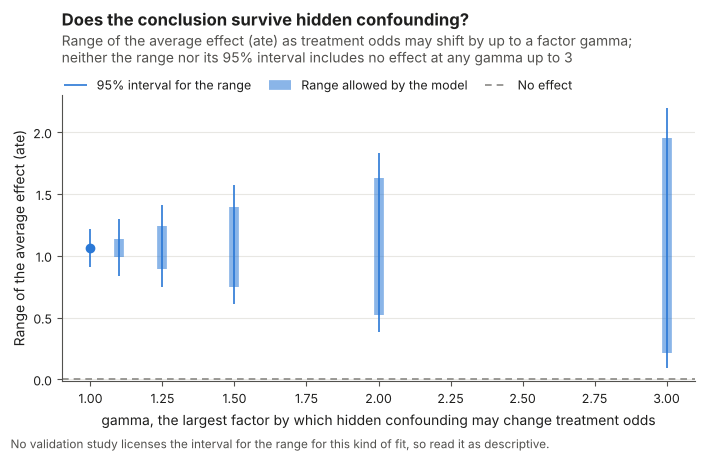

In [10]:
gammas = (1.0, 1.1, 1.25, 1.5, 2.0, 3.0)
gamma_bounds = result.sensitivity.marginal_bounds(gamma=gammas)
columns = ["gamma", "lower", "upper", "lower_limit", "upper_limit"]
print(gamma_bounds.to_frame()[columns].round(3).to_string(index=False))
gamma_fig = gamma_bounds.plot()

Gamma is the largest factor by which a hidden confounder could change a patient's odds of the offer,
beyond what the recorded characteristics explain. At each gamma the thick bar is the range of effects
the model allows, and the thin line is its 95% interval. At gamma 1, with no hidden confounding, the
range is one dot at 1.061. That estimate uses predictions for each row from models trained without
that row, so it differs a little from the TMLE value.

The range widens as gamma grows, to a range of 0.214 to 1.956 at gamma 3, where the lowest interval limit
is still above zero, at 0.090. So the effect stays positive up to gamma 3, while its size could be
almost anything. The note under the figure calls the interval descriptive, because no simulation
study covers it for this kind of fit.

## What if we add a confounder we invent?

 treatment_strength  outcome_strength  estimate  displacement
                0.0               0.0     1.093         0.000
                0.0               0.5     1.102         0.009
                0.0               1.0     1.111         0.018
                0.0               2.0     1.131         0.038
                0.1               0.0     0.549        -0.544
                0.1               0.5     0.590        -0.503
                0.1               1.0     0.638        -0.455
                0.1               2.0     0.733        -0.360
                0.2               0.0     0.454        -0.639
                0.2               0.5     0.467        -0.626
                0.2               1.0     0.482        -0.611
                0.2               2.0     0.511        -0.582
                0.4               0.0     0.142        -0.951
                0.4               0.5     0.152        -0.941
                0.4               1.0     0.163        -0.930
        

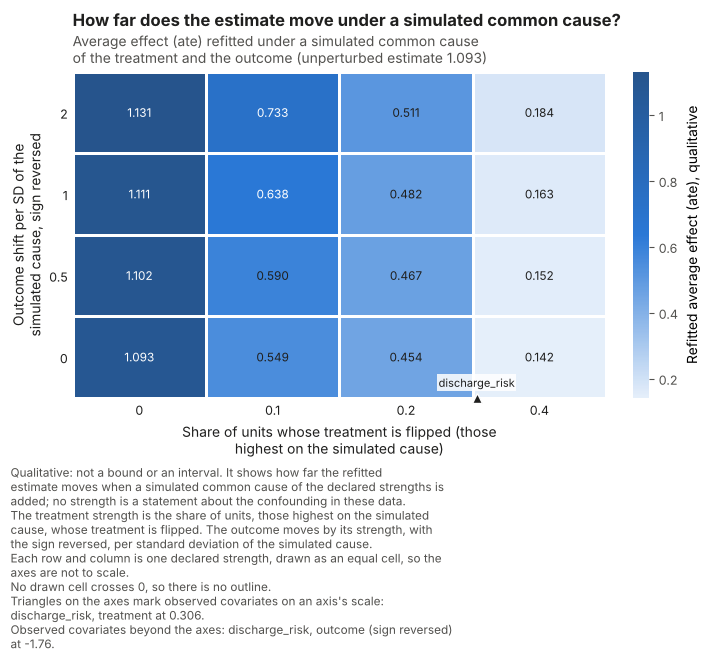

In [11]:
from cleverly.sensitivity import ConfounderStrengthGrid

# For your own data, name your strongest recorded confounder in benchmark_covariates.
surface = result.sensitivity.simulated_confounding(
    grid=ConfounderStrengthGrid(treatment=(0.0, 0.1, 0.2, 0.4), outcome=(0.0, 0.5, 1.0, 2.0)),
    benchmark_covariates=("discharge_risk",),
    random_state=21,
)
cells = surface.to_frame()
shown = ["treatment_strength", "outcome_strength", "estimate", "displacement"]
print(cells[shown].round(3).to_string(index=False))
print()
print(
    surface.calibration_frame()[["covariate", "role", "strength"]].round(3).to_string(index=False)
)
surface_fig = plotting.confounding(surface)

Instead of bounding a hidden confounder, `cleverly` can add an invented one to the data and
re-estimate. Each cell is one invented confounder. The horizontal axis is the share of patients
whose offer is flipped, those highest on the invented cause. The vertical axis is how strongly the
invented cause shifts the score. The top-left cell is the unchanged estimate, 1.093.

The estimate shrinks as more offers are flipped, to 0.142 at 0.4 with no shift in the score, but no
cell crosses zero. The triangle marks the recorded `discharge_risk` at 0.306 on the horizontal axis,
a yardstick for the invented strengths. The note calls the map qualitative: it shows how far an
invented confounder moves the estimate, and it is neither a bound nor an interval.

## What if the missing answers differ from the recorded ones?

In [12]:
from cleverly.datasets import make_missing_outcome

survey, survey_truth = make_missing_outcome(n=1_500, seed=71)
survey = survey.rename(
    columns={
        "Y": "satisfaction",
        "A": "navigation_offer",
        "W1": "discharge_risk",
        "W2": "prior_utilization",
        "W3": "medication_burden",
        "Delta": "responded",
    }
)
survey_study = CausalStudy(
    survey,
    design=PointTreatment(
        outcome="satisfaction",
        treatment="navigation_offer",
        adjustment=tuple(covariates),
        missingness="responded",
    ),
)
survey_result = survey_study.identify(ATE(reference=0)).estimate(
    missingness_learner=LogisticRegression(max_iter=1000), **fit_settings
)
print(f"share of satisfaction scores missing: {1 - survey['responded'].mean():.3f}")
print(
    survey_result.to_frame()[["estimand", "psi", "ci_lower", "ci_upper"]]
    .round(3)
    .to_string(index=False)
)

share of satisfaction scores missing: 0.222
estimand   psi  ci_lower  ci_upper
     ate 1.132     1.009     1.255


This question needs missing outcomes, so it uses a second simulated dataset. It is a satisfaction
survey in which 0.222 of the scores are missing because the patient did not answer. The main
analysis assumes that a patient who did not answer would have scored like an answering patient with
the same recorded characteristics (missing at random). It estimates 1.132, with an interval of 1.009
to 1.255. The column `responded` marks who answered, and `missingness_learner` is the model of who
answers.

 gamma   psi  ci_lower  ci_upper
   0.0 1.132     1.009     1.255
   0.5 0.858     0.735     0.981
   1.0 0.585     0.462     0.708
   1.5 0.341     0.219     0.464
   2.0 0.144     0.021     0.267
gamma at which the estimate reaches 0: 2.490


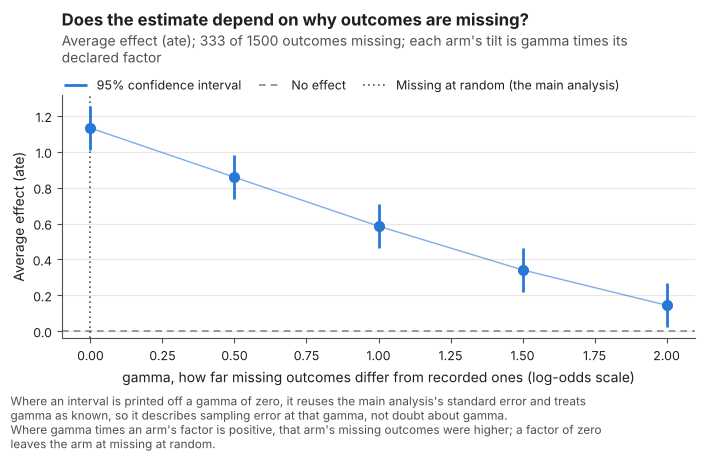

In [13]:
from cleverly.sensitivity import missingness_tilt

# A positive gamma lowers the missing scores of patients who were offered and leaves those of
# patients who were not offered as the main analysis assumes. For your own data, choose the
# direction you can defend.
direction = {0: 0.0, 1: -1.0}
tilt = missingness_tilt(survey_result, (0.0, 0.5, 1.0, 1.5, 2.0), arm_gamma=direction)
print(tilt.to_frame()[["gamma", "psi", "ci_lower", "ci_upper"]].round(3).to_string(index=False))
tipping = survey_result.sensitivity.tipping_gamma(arm_gamma=direction)
print(f"gamma at which the estimate reaches 0: {tipping:.3f}")
tilt_fig = tilt.plot()

Gamma measures how far the missing scores differ from that assumption, on a log-odds scale, and
gamma 0 is the main analysis. Here a positive gamma lowers the missing scores of offered patients
and leaves the others as the main analysis assumes. The estimate falls from 1.132 to 0.144 at gamma
2.0 and reaches zero at gamma 2.490. The intervals show sampling error at each gamma and nothing
more, and the note under the figure says so.

The figure cannot say which gamma is plausible. That takes knowledge of why patients did not answer,
and the [missing survey answers](survey-nonresponse.ipynb) page turns gamma into a drop in the
average missing score.

## Do a method's intervals cover the true value?

true average effect: 1.750
intervals that cover it: 44% of 100
intervals wholly below it: 56
intervals wholly above it: 0


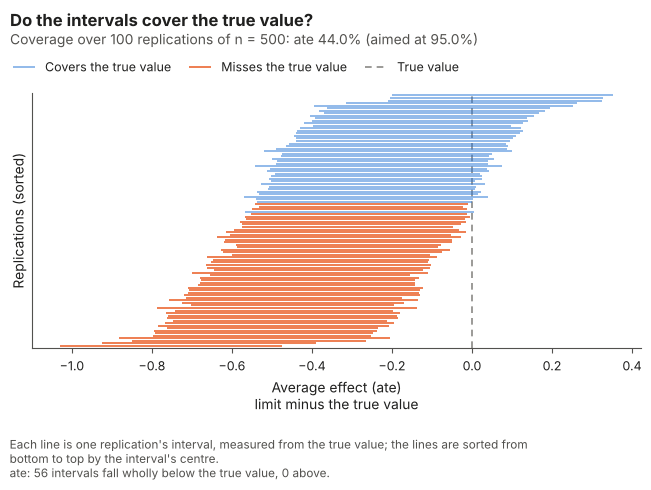

In [14]:
from cleverly.datasets import nonlinear_dgp
from cleverly.estimators import TMLE
from cleverly.validation import CoverageStudy

# A simulation: draw 100 fresh samples of 500 patients from a process whose answer is known, fit
# the same linear models to each, and keep every interval.
coverage_study = CoverageStudy(
    dgp=nonlinear_dgp(),
    estimator=lambda: TMLE(
        outcome_learner=LinearRegression(),
        treatment_learner=LogisticRegression(max_iter=1000),
        cross_fit=False,
    ),
    n=500,
    n_replicates=100,
    estimands=("ate",),
    seed=7,
).run()
records = pd.DataFrame(
    [
        {"low": record.lower, "high": record.upper, "covered": record.covered}
        for record in coverage_study.replications
    ]
)
truth_ate = coverage_study.replications[0].truth
print(f"true average effect: {truth_ate:.3f}")
print(f"intervals that cover it: {records['covered'].mean():.0%} of {len(records)}")
print(f"intervals wholly below it: {(records['high'] < truth_ate).sum()}")
print(f"intervals wholly above it: {(records['low'] > truth_ate).sum()}")
zipper_fig = plotting.zipper(coverage_study)

This question needs a process whose answer you know, so it checks a method and not your data. Each
line is the interval from one simulated sample, drawn relative to the true value (the dashed line)
and sorted by its centre, and orange lines miss. Only 44% of the 100 intervals cover the true effect
of 1.750, against the 95% aimed at, and all 56 misses lie below it.

Misses piled at one end mean the estimates are biased, here because linear models cannot follow this
process. Misses split between both ends would mean the intervals are too narrow. A coverage number
alone cannot tell the two apart.

## What the figures can and can't tell you

The page shows one simulated draw, so each reading describes these data and is no general rule. The
three confounding figures show how strong a missing confounder would have to be, or how far an
invented one moves the estimate, and none shows whether one exists. A plot draws no more than the fit
holds, so a missing interval is the fit's answer and not a limit of the plot. On real data there is no true
value, so `truth=` drops out and the last figure needs a simulation that you design.

## Where to go next

The [one treatment, one outcome](point-treatment-tmle.ipynb) page uses the overlap figure and a
confounding map on a fuller analysis, and [who gains most from a coupon](conditional-effects.ipynb)
draws an effect over age. [Readmission by day 30, 60 and 90](discharge-to-readmission.ipynb) draws
risk over time. The [plotting reference](../api/plotting.md) lists every function, including the
ones this page skips, and [results, inference, and assessment](../user-guide/results-assessment.md)
explains the summaries that the figures draw from.